!pip install yfinance

In [7]:
import yfinance as yf
import pandas as pd
import numpy as np

# Mapped ticker list
tickers = [
    'VWRA.L', 'VOO', 'CSPX.L', 'QQQ', 'SMH.L',
    'LSEG.L', 'REL.L', 'NVDA', 'PLTR', '3IN.L',
    'RR.L', 'DELL', '^GSPC'
]

# Download data safely
df = yf.download(tickers, start="2026-07-17", end="2026-10-31")

# Extract price columns regardless of yfinance version
if 'Adj Close' in df.columns:
    data = df['Adj Close']
elif 'Close' in df.columns:
    data = df['Close']
else:
    data = df

# Calculate daily log returns
returns = np.log(data / data.shift(1)).dropna()

# Generate annualized covariance matrix
cov_matrix = returns.cov() * 252

# Print returns summary
print("Daily Returns Head:")
print(returns.head())

print("\nAnnualized Covariance Matrix:")
print(cov_matrix)

/tmp/ipykernel_673/670719930.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(tickers, start="2026-07-17", end="2026-10-31")
[*********************100%***********************]  13 of 13 completed


Daily Returns Head:
Ticker         3IN.L    CSPX.L      DELL    LSEG.L      NVDA      PLTR  \
Date                                                                     
2026-07-20  0.000000  0.001664 -0.037166 -0.015038  0.002315  0.018486   
2026-07-21  0.000000  0.002602  0.058331 -0.027977  0.019534 -0.016374   
2026-07-22  0.006374  0.001781  0.089071  0.009490  0.022751 -0.062922   
2026-07-23 -0.020540 -0.016692 -0.005584 -0.013218 -0.015684 -0.009680   
2026-07-24  0.000000  0.007234 -0.004197  0.023758 -0.009240 -0.003654   

Ticker           QQQ     REL.L      RR.L     SMH.L       VOO    VWRA.L  \
Date                                                                     
2026-07-20  0.001049  0.008775 -0.005581  0.023195 -0.001406  0.001817   
2026-07-21  0.018377 -0.025746  0.010694  0.037441  0.008262  0.006067   
2026-07-22 -0.005119  0.000000  0.014035  0.012414 -0.001222  0.001167   
2026-07-23 -0.019166 -0.001223 -0.023992 -0.018405 -0.012332 -0.015920   
2026-07-24 -0.011

/tmp/ipykernel_673/3106740435.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(all_tickers, start="2026-07-17", end="2026-10-31")
[*********************100%***********************]  13 of 13 completed


=== PORTFOLIO QUANTITATIVE SUMMARY ===
Annualized Return:    15.06%
Annualized Volatility:13.34%
Sharpe Ratio:         0.83
Portfolio Beta (S&P): 1.06

=== OPTIMIZED WEIGHTS (MARKOWITZ EFFICIENCY) ===
VWRA.L   Current:  22.3%  |  Optimized:   0.0%
VOO      Current:  19.1%  |  Optimized:   0.0%
CSPX.L   Current:  12.7%  |  Optimized:   0.0%
QQQ      Current:   9.6%  |  Optimized:   0.0%
SMH.L    Current:   9.6%  |  Optimized:   0.0%
LSEG.L   Current:   6.4%  |  Optimized:   0.0%
REL.L    Current:   6.4%  |  Optimized:  66.3%
NVDA     Current:   3.2%  |  Optimized:   3.7%
PLTR     Current:   3.2%  |  Optimized:  19.5%
3IN.L    Current:   3.2%  |  Optimized:   0.0%
RR.L     Current:   3.2%  |  Optimized:   0.0%
DELL     Current:   1.3%  |  Optimized:  10.5%


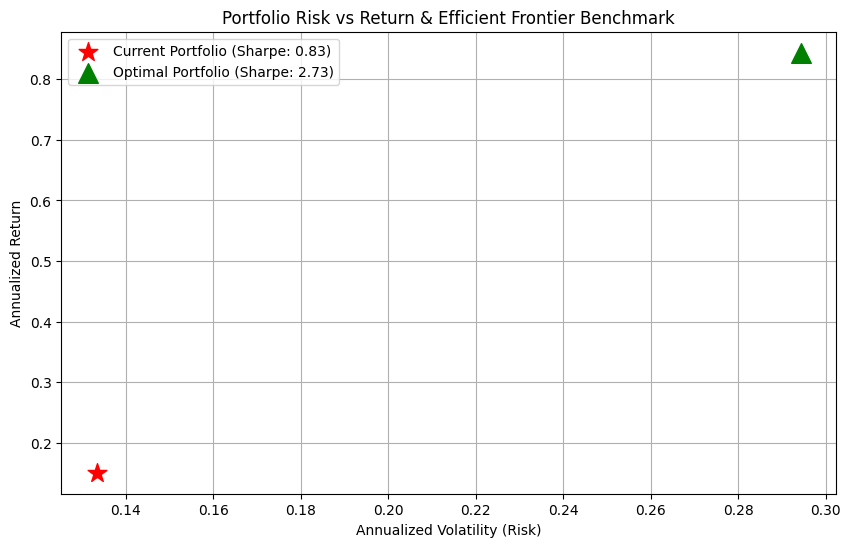

In [8]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Setup Tickers and Portfolio Weights from your CSV allocation
tickers = ['VWRA.L', 'VOO', 'CSPX.L', 'QQQ', 'SMH.L', 'LSEG.L', 'REL.L', 'NVDA', 'PLTR', '3IN.L', 'RR.L', 'DELL']
benchmark = '^GSPC'

# Portfolio capital allocation weights (£100k scale)
weights = np.array([35000, 30000, 20000, 15000, 15000, 10000, 10000, 5000, 5000, 5000, 5000, 2000])
weights = weights / np.sum(weights)

# 2. Download historical market data
all_tickers = tickers + [benchmark]
df = yf.download(all_tickers, start="2026-07-17", end="2026-10-31")
data = df['Adj Close'] if 'Adj Close' in df.columns else df['Close']
returns = np.log(data / data.shift(1)).dropna()

asset_returns = returns[tickers]
bm_returns = returns[benchmark]

# 3. Calculate Portfolio Statistics
trading_days = 252
rf_rate = 0.04  # 4.0% risk-free rate assumption

mean_daily_ret = asset_returns.mean()
cov_matrix = asset_returns.cov() * trading_days

port_return = np.sum(mean_daily_ret * weights) * trading_days
port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
sharpe_ratio = (port_return - rf_rate) / port_vol

# Calculate Portfolio Beta relative to S&P 500
port_daily_returns = asset_returns.dot(weights)
covariance_with_bm = np.cov(port_daily_returns, bm_returns)[0][1]
bm_variance = np.var(bm_returns)
port_beta = covariance_with_bm / bm_variance

print("=== PORTFOLIO QUANTITATIVE SUMMARY ===")
print(f"Annualized Return:    {port_return:.2%}")
print(f"Annualized Volatility:{port_vol:.2%}")
print(f"Sharpe Ratio:         {sharpe_ratio:.2f}")
print(f"Portfolio Beta (S&P): {port_beta:.2f}")

# 4. Markowitz Optimization (Max Sharpe Portfolio)
def min_func_sharpe(w):
    p_ret = np.sum(asset_returns.mean() * w) * trading_days
    p_vol = np.sqrt(np.dot(w.T, np.dot(cov_matrix, w)))
    return -(p_ret - rf_rate) / p_vol

constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0, 1) for _ in range(len(tickers)))
opt_results = minimize(min_func_sharpe, len(tickers)*[1./len(tickers)], method='SLSQP', bounds=bounds, constraints=constraints)

opt_weights = opt_results.x
opt_ret = np.sum(mean_daily_ret * opt_weights) * trading_days
opt_vol = np.sqrt(np.dot(opt_weights.T, np.dot(cov_matrix, opt_weights)))
opt_sharpe = -opt_results.fun

print("\n=== OPTIMIZED WEIGHTS (MARKOWITZ EFFICIENCY) ===")
for ticker, w_curr, w_opt in zip(tickers, weights, opt_weights):
    print(f"{ticker:<8} Current: {w_curr:>6.1%}  |  Optimized: {w_opt:>6.1%}")

# 5. Plot Risk vs Return
plt.figure(figsize=(10, 6))
plt.scatter(port_vol, port_return, color='red', marker='*', s=200, label=f'Current Portfolio (Sharpe: {sharpe_ratio:.2f})')
plt.scatter(opt_vol, opt_ret, color='green', marker='^', s=200, label=f'Optimal Portfolio (Sharpe: {opt_sharpe:.2f})')
plt.title('Portfolio Risk vs Return & Efficient Frontier Benchmark')
plt.xlabel('Annualized Volatility (Risk)')
plt.ylabel('Annualized Return')
plt.legend()
plt.grid(True)
plt.show()

# Quantitative Portfolio Performance Attribution & Markowitz Optimization
**Author:** James Latimer  
**Target:** UCAS Super-Curricular Research Project (Maths / Quantitative Economics)
